# Refresher on numpy, matplotlib, and pandas

### importing all the libraries

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### numpy refresher first
create an array and perform different operations on it

In [5]:
goals = np.array([2, 3, 7, 3, 4, 5])
print(goals.sum)  # sum of every number in array
print(goals.mean()) # average of the array
print(goals * 2) # every number in the array multiplied by 2
print(goals.std()) # standard deviation of the array

<built-in method sum of numpy.ndarray object at 0x0000020F54825590>
4.0
[ 4  6 14  6  8 10]
1.632993161855452


In [6]:
print(goals[goals > 3]) # filtering, gives the values greater than 3 in the array

[7 4 5]


In [7]:
newGoals = np.array([2, 4, 13, 6, 8, 9])
print(newGoals.sum()) # sum of every number in array
print(newGoals.max()) # max value in the array
print(newGoals.min()) # min value in the array
print(newGoals[newGoals < 3]) # filtering, gives the values less than 3 in the array

42
13
2
[2]


### pandas now

In [8]:
df = pd.read_csv("E0.csv")
df.head() # first five rows

,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFECAHH,BFECAHA
0,E0,15/08/2025,20:00,Liverpool,Bournemouth,4,2,H,1,0,...,2.03,1.78,2.07,1.85,2.03,1.88,1.94,1.76,2.14,1.86
1,E0,16/08/2025,12:30,Aston Villa,Newcastle,0,0,D,0,0,...,2.05,1.80,2.02,1.89,2.06,1.80,1.95,1.74,2.14,1.86
2,E0,16/08/2025,15:00,Brighton,Fulham,1,1,D,0,0,...,1.83,2.03,1.93,2.00,1.84,2.03,1.80,1.96,1.91,2.08
3,E0,16/08/2025,15:00,Sunderland,West Ham,3,0,H,0,0,...,1.95,1.90,1.97,1.95,1.95,1.94,1.86,1.78,2.02,1.97
4,E0,16/08/2025,15:00,Tottenham,Burnley,3,0,H,1,0,...,1.98,1.88,1.99,1.93,1.98,1.91,1.88,1.83,2.07,1.92


In [9]:
df.shape # dimensions rxc

(380, 132)

In [10]:
df.columns # column names

Index(['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR',
       'HTHG', 'HTAG',
       ...
       'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA',
       'AvgCAHH', 'AvgCAHA', 'BFECAHH', 'BFECAHA'],
      dtype='str', length=132)

In [11]:
df = df[["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR", "HTHG", "HTAG", "HTR", "HS", "AS"]] # keeping only certain columns
df.head()

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS
0,15/08/2025,Liverpool,Bournemouth,4,2,H,1,0,H,19,10
1,16/08/2025,Aston Villa,Newcastle,0,0,D,0,0,D,3,16
2,16/08/2025,Brighton,Fulham,1,1,D,0,0,D,10,7
3,16/08/2025,Sunderland,West Ham,3,0,H,0,0,D,10,12
4,16/08/2025,Tottenham,Burnley,3,0,H,1,0,H,16,14


In [12]:
df["FTHG"].mean().round(2) # average of fulltime home goals

np.float64(1.53)

In [13]:
df.info() # column, number of non-empty values, type

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      380 non-null    str  
 1   HomeTeam  380 non-null    str  
 2   AwayTeam  380 non-null    str  
 3   FTHG      380 non-null    int64
 4   FTAG      380 non-null    int64
 5   FTR       380 non-null    str  
 6   HTHG      380 non-null    int64
 7   HTAG      380 non-null    int64
 8   HTR       380 non-null    str  
 9   HS        380 non-null    int64
 10  AS        380 non-null    int64
dtypes: int64(6), str(5)
memory usage: 32.8 KB


In [14]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True) # changes the datatype of the date column from str to datetime
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      380 non-null    datetime64[us]
 1   HomeTeam  380 non-null    str           
 2   AwayTeam  380 non-null    str           
 3   FTHG      380 non-null    int64         
 4   FTAG      380 non-null    int64         
 5   FTR       380 non-null    str           
 6   HTHG      380 non-null    int64         
 7   HTAG      380 non-null    int64         
 8   HTR       380 non-null    str           
 9   HS        380 non-null    int64         
 10  AS        380 non-null    int64         
dtypes: datetime64[us](1), int64(6), str(4)
memory usage: 32.8 KB


In [15]:
df["TotalGoals"] = df["FTHG"] + df["FTAG"] # adding a new columns that shows the total goals in a game
df.head()

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,TotalGoals
0,2025-08-15,Liverpool,Bournemouth,4,2,H,1,0,H,19,10,6
1,2025-08-16,Aston Villa,Newcastle,0,0,D,0,0,D,3,16,0
2,2025-08-16,Brighton,Fulham,1,1,D,0,0,D,10,7,2
3,2025-08-16,Sunderland,West Ham,3,0,H,0,0,D,10,12,3
4,2025-08-16,Tottenham,Burnley,3,0,H,1,0,H,16,14,3


In [16]:
df["TotalGoals"].mean() # average of total goals

np.float64(2.75)

In [17]:
df["TotalGoals"].max() # finds what was the highest number of goals scored in a game

np.int64(9)

In [18]:
df[df["TotalGoals"] >= 5] # games in which 5 or more goals were scored

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,TotalGoals
0,2025-08-15,Liverpool,Bournemouth,4,2,H,1,0,H,19,10,6
10,2025-08-22,West Ham,Chelsea,1,5,A,1,3,A,12,12,6
15,2025-08-23,Arsenal,Leeds,5,0,H,2,0,H,18,3,5
19,2025-08-25,Newcastle,Liverpool,2,3,A,0,1,A,10,5,5
21,2025-08-30,Man United,Burnley,3,2,H,1,0,H,26,6,5
24,2025-08-30,Wolves,Everton,2,3,A,1,2,A,12,10,5
54,2025-09-27,Man City,Burnley,5,1,H,1,1,D,21,9,6
73,2025-10-18,Crystal Palace,Bournemouth,3,3,D,0,2,A,20,8,6
83,2025-10-25,Man United,Brighton,4,2,H,2,0,H,13,17,6
84,2025-10-25,Brentford,Liverpool,3,2,H,2,1,H,17,18,5


In [19]:
len(df[df["TotalGoals"] >= 5]) # number of games with 5 or more goals scored

49

In [20]:
df[df["HomeTeam"] == "Man City"] # games in which city played at home

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,TotalGoals
11,2025-08-23,Man City,Tottenham,0,2,A,0,2,A,10,12,2
39,2025-09-14,Man City,Man United,3,0,H,1,0,H,13,12,3
54,2025-09-27,Man City,Burnley,5,1,H,1,1,D,21,9,6
74,2025-10-18,Man City,Everton,2,0,H,0,0,D,19,5,2
98,2025-11-02,Man City,Bournemouth,3,1,H,2,1,H,15,8,4
109,2025-11-09,Man City,Liverpool,3,0,H,2,0,H,14,7,3
121,2025-11-29,Man City,Leeds,3,2,H,2,0,H,18,9,5
143,2025-12-06,Man City,Sunderland,3,0,H,2,0,H,18,8,3
163,2025-12-20,Man City,West Ham,3,0,H,2,0,H,17,7,3
199,2026-01-04,Man City,Chelsea,1,1,D,1,0,H,14,8,2


In [21]:
df[(df["HomeTeam"] == "Man City") & (df["FTR"] == "H")] # games in which city played at home and won

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,TotalGoals
39,2025-09-14,Man City,Man United,3,0,H,1,0,H,13,12,3
54,2025-09-27,Man City,Burnley,5,1,H,1,1,D,21,9,6
74,2025-10-18,Man City,Everton,2,0,H,0,0,D,19,5,2
98,2025-11-02,Man City,Bournemouth,3,1,H,2,1,H,15,8,4
109,2025-11-09,Man City,Liverpool,3,0,H,2,0,H,14,7,3
121,2025-11-29,Man City,Leeds,3,2,H,2,0,H,18,9,5
143,2025-12-06,Man City,Sunderland,3,0,H,2,0,H,18,8,3
163,2025-12-20,Man City,West Ham,3,0,H,2,0,H,17,7,3
223,2026-01-24,Man City,Wolves,2,0,H,2,0,H,11,11,2
256,2026-02-11,Man City,Fulham,3,0,H,3,0,H,13,14,3


In [22]:
df[df["FTR"] == "D"] # games in which the game ended in a draw

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,TotalGoals
1,2025-08-16,Aston Villa,Newcastle,0,0,D,0,0,D,3,16,0
2,2025-08-16,Brighton,Fulham,1,1,D,0,0,D,10,7,2
6,2025-08-17,Chelsea,Crystal Palace,0,0,D,0,0,D,19,12,0
16,2025-08-24,Crystal Palace,Nott'm Forest,1,1,D,1,0,H,8,9,2
18,2025-08-24,Fulham,Man United,1,1,D,0,0,D,13,10,2
...,...,...,...,...,...,...,...,...,...,...,...,...
365,2026-05-17,Wolves,Fulham,1,1,D,1,1,D,11,13,2
368,2026-05-19,Bournemouth,Man City,1,1,D,1,0,H,10,14,2
371,2026-05-24,Burnley,Wolves,1,1,D,0,1,A,16,16,2
374,2026-05-24,Liverpool,Brentford,1,1,D,0,0,D,24,11,2


In [23]:
df[(df["FTHG"] == 0) & (df["FTAG"] >= 3)] # games in which the away team won scoring 3 or more goals while the home team scored 0

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,TotalGoals
5,2025-08-16,Wolves,Man City,0,4,A,0,2,A,9,15,4
27,2025-08-31,Nott'm Forest,West Ham,0,3,A,0,0,D,11,12,3
29,2025-08-31,Aston Villa,Crystal Palace,0,3,A,0,1,A,13,6,3
36,2025-09-13,West Ham,Tottenham,0,3,A,0,0,D,7,14,3
70,2025-10-18,Nott'm Forest,Chelsea,0,3,A,0,0,D,12,17,3
89,2025-10-26,Everton,Tottenham,0,3,A,0,2,A,12,7,3
114,2025-11-22,Liverpool,Nott'm Forest,0,3,A,0,1,A,21,15,3
154,2025-12-14,Crystal Palace,Man City,0,3,A,0,1,A,16,7,3
231,2026-01-31,Leeds,Arsenal,0,4,A,0,2,A,3,14,4
308,2026-03-22,Tottenham,Nott'm Forest,0,3,A,0,1,A,14,8,3


In [24]:
df.sort_values("TotalGoals", ascending=False).head() # sorts games in descending order of total goals

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,TotalGoals
131,2025-12-02,Fulham,Man City,4,5,A,1,3,A,12,11,9
159,2025-12-15,Man United,Bournemouth,4,4,D,2,1,H,25,14,8
274,2026-02-28,Liverpool,West Ham,5,2,H,3,0,H,18,11,7
273,2026-02-28,Burnley,Brentford,3,4,A,1,3,A,12,16,7
208,2026-01-07,Newcastle,Leeds,4,3,H,1,2,A,18,14,7


In [25]:
df.groupby("HomeTeam")["FTHG"].mean().sort_values(ascending=False)

HomeTeam
Man City          2.368421
Arsenal           2.157895
Man United        2.052632
Newcastle         1.894737
Liverpool         1.789474
Brentford         1.736842
Aston Villa       1.684211
Fulham            1.578947
Brighton          1.578947
Bournemouth       1.526316
Leeds             1.526316
West Ham          1.421053
Everton           1.368421
Chelsea           1.368421
Sunderland        1.315789
Tottenham         1.157895
Nott'm Forest     1.052632
Crystal Palace    1.000000
Wolves            1.000000
Burnley           0.947368
Name: FTHG, dtype: float64

In [26]:
df.groupby("HomeTeam")["HS"].sum().sort_values(ascending=False)

HomeTeam
Man United        340
Liverpool         327
Man City          312
Arsenal           305
Chelsea           288
Nott'm Forest     285
Bournemouth       275
Newcastle         272
Leeds             272
Fulham            269
Brighton          262
Aston Villa       261
Crystal Palace    253
Tottenham         241
Everton           232
Brentford         228
Sunderland        228
West Ham          210
Burnley           206
Wolves            193
Name: HS, dtype: int64

In [27]:
df[["Date", "HomeTeam", "AwayTeam", "TotalGoals"]].sort_values("TotalGoals", ascending=False).head(3)

,Date,HomeTeam,AwayTeam,TotalGoals
131,2025-12-02,Fulham,Man City,9
159,2025-12-15,Man United,Bournemouth,8
274,2026-02-28,Liverpool,West Ham,7


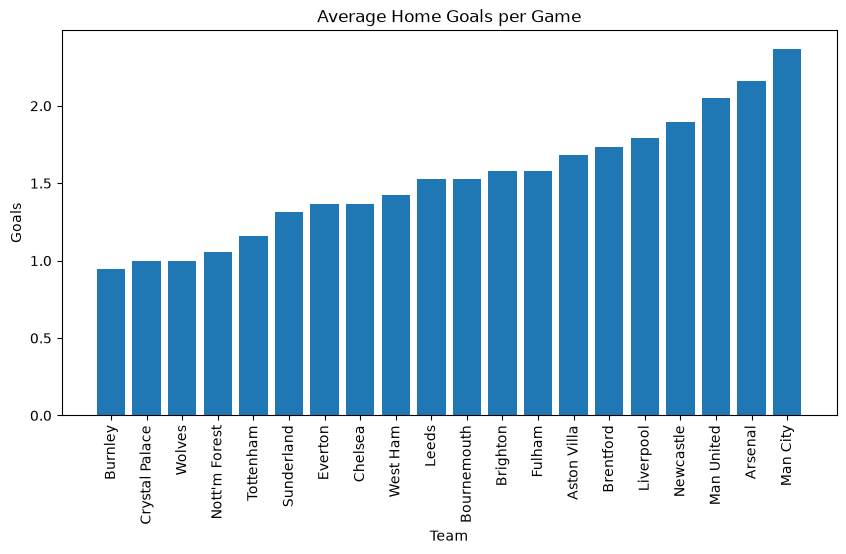

In [28]:
homeGoals = df.groupby("HomeTeam")["FTHG"].mean().sort_values()
fig, ax = plt.subplots(figsize=(10,5))
ax.bar(homeGoals.index, homeGoals.values)
ax.set_title("Average Home Goals per Game")
ax.set_xlabel("Team")
ax.set_ylabel("Goals")
plt.xticks(rotation=90)
plt.show()